# Figure 2
ODE and stochastic molecular model implementation

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sys.path.insert(0, os.getcwd() + "/../../Python/cellular_cycle") #add a pathway to the model #not sure about how to use folder dependency, to change
sys.path.insert(0, os.getcwd() + "/../../Python/fit")

##Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count
from Austin_proliferation_model_concentration_5 import model
model_concentration=model
from Austin_proliferation_model_population_5 import model
model_population=model

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator

In [2]:
#change the model parameters of the model if needed
omega = 200
new_param = pd.read_csv(os.getcwd() + "/../../umap_window/parameters.csv") 
del new_param['Stress']
#for key in new_param.keys():
#    if model_population.parameters[key].value != new_param[key][0]:
#        model_population.parameters[key].value = new_param[key]
#    if model_concentration.parameters[key].value != new_param[key][0]:
#        model_concentration.parameters[key].value = new_param[key]

# Directory containing cell fate data
from pathlib import Path

DATADIR = Path('../../Data/Exp_Intermitotic_Times/')

In [6]:
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

2022-08-17 21:38:10.073 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


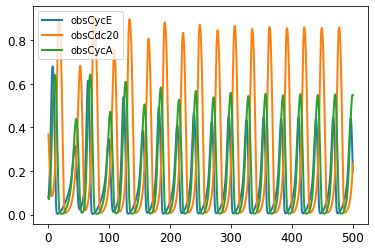

In [20]:
#ODE simulation

t = np.linspace(0, 500, 50001)
simres = ScipyOdeSimulator(model_concentration, t, verbose=False).run(); #deterministic simulation
yout = simres.all;
observables=['obsCycE','obsCdc20', 'obsCycA']; #plot Cyclin E, Cdc20 and Cyclin A

for obs in range(3) :
    plt.plot(t,yout[observables[obs]], label=observables[obs], lw=2)
plt.legend(loc=0)
plt.show()

499.99

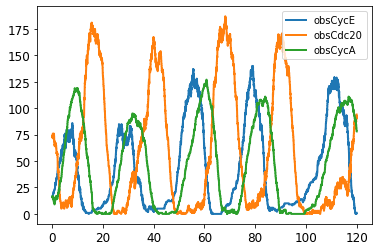

CPU times: total: 7.64 s
Wall time: 19.8 s


In [25]:
%%time

### Stochastic simulation

t = np.linspace(0, 120, 120001);
sim = BngSimulator(model_population, tspan=t, verbose=False); #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=33); #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
yout = simres.observables;
observables=['obsCycE','obsCdc20', 'obsCycA']; #plot Cyclin E, Cdc20 and Cyclin A


for obs in range(3) :    
    plt.plot(t,yout[observables[obs]], label=observables[obs], lw=2)
plt.legend(loc=0)
plt.show()

In [9]:
#from runAKTERK_2_starting_at_mitosis import runAKTERK #Cell population simulation
#from runStochCell import runStochcell #Simulate the biochemical model with ODEs
from runAKTERK_2 import runAKTERK #Simulate a population of cells from independants biochemical models
from runStochCell import runStochcell

from retrieve_cellState_dw import retrieve_cellState #
from call_cell_events import call_events #
from SMs_G1s_IMTs_extraction import IMTs

import fracprolif as fp
from rbf_mmd import nmmd2_rbf

In [10]:
%%time

run_time=120 #how long is the experiment
observed_cells_time=120 #how long are we looking at new cells
nber_of_starting_cells=1 #size of initial population
index="_" #to be removed...
condition="_" #to be removed...


#(cells, cell_count) = runAKTERK(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition);
(cells, cell_count) = runAKTERK(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition);
#index and conditions to save the identity of the simulation (to remove?)

2022-08-17 16:28:49.742 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


CPU times: total: 19.8 s
Wall time: 46.8 s


In [14]:
test = cells['molecules']

In [15]:
test

[{'obsSkp2': [6.0,
   6.0,
   6.0,
   6.0,
   6.0,
   6.0,
   7.0,
   7.0,
   7.0,
   7.0,
   7.0,
   7.0,
   7.0,
   7.0,
   7.0,
   8.0,
   8.0,
   8.0,
   9.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   10.0,
   12.0,
   12.0,
   13.0,
   13.0,
   13.0,
   12.0,
   12.0,
   12.0,
   11.0,
   11.0,
   11.0,
   11.0,
   12.0,
   12.0,
   12.0,
   12.0,
   12.0,
   12.0,
   12.0,
   12.0,
   12.0,
   12.0,
   12.0,
   11.0,
   11.0,
   11.0,
   11.0,
   11.0,
   11.0,
   11.0,
   11.0,
   11.0,
   11.0,
   11.0,
   11.0,
   11.0,
   11.0,
   12.0,
   12.0,
   12.0,
   12.0,
   13.0,
   13.0,
   13.0,
   13.0,
   13.0,
   13.0,
   13.0,
   13.0,
   13.0,
   13.0,
   14.0,
   14.0,
   13.0,
   13.0,
   13.0,
   13.0,
   13.0,
   13.0,
   14.0,
   15.0,
   15.0,
   14.0,
   15.0,
   15.0,
   15.0,
   15.0,
   14.0,
   13.0,
   13.0,
   13.0,
   13.0,
   14.0,
   14.0,
   14.0,
